# Compute abundance change for each allele

This script takes in the single-cell FACS data as input, applies various filtering criteria, and then produces a z-score for the abundance of each allele relative to the reference on the same plate.

In [1]:
import pandas as pd
import numpy as np
from random import choice

import process_dualipa as proc

In [2]:
dualipa_inputs = "../1_inputs"
dualipa_outputs = "../3_outputs"

n_cell_threshold = 800
wt_gfp_threshold = 100

In [3]:
# Read in single-cell measurements
pDEST_DUAL_df = pd.read_parquet(f"{dualipa_outputs}/facs_single_cell.parquet")

# Filter to only keep wells with more than 800 cells
pDEST_DUAL_df = pDEST_DUAL_df[pDEST_DUAL_df['n_cells'] > n_cell_threshold]

In [4]:
# get the mean and median measurements per well
keep_cols = ['symbol', 'node_type', 'nt_change','aa_change', 'pla', 'well', 'coordinates', 'n_cells', 'orf_id', 'mut_id', 'valid_well']

pDEST_DUAL_avg_df = pDEST_DUAL_df[keep_cols + ['avg_gfp', 'avg_mcherry','avg_GFP_mCherry_ratio']].drop_duplicates()
pDEST_DUAL_median_df = pDEST_DUAL_df[keep_cols + ['median_gfp', 'median_mcherry','median_GFP_mCherry_ratio']].drop_duplicates()

In [5]:
# _d objects: mean or median GFP_mCherry ratio of each unique (wt orf, plate) combination
# _l objects: list of WT:WT abundances (GFP:mCherry ratios) to estimate assay variability
wt_avg_d, wt_ratio_l = proc.get_wt_variability_d(pDEST_DUAL_avg_df, pDEST_DUAL_df)
wt_median_d, wt_ratio_l_median = proc.get_wt_variability_d_median(pDEST_DUAL_median_df, pDEST_DUAL_df)

In [6]:
# Must be two WT replicates on same plate to compute the ratio, otherwise we return a NaN
pDEST_DUAL_avg_allele_df = proc.get_pDEST_DUAL_avg_allele_df(pDEST_DUAL_avg_df, wt_avg_d, wt_ratio_l)
pDEST_DUAL_median_allele_df = proc.get_pDEST_DUAL_median_allele_df(pDEST_DUAL_median_df, wt_median_d, wt_ratio_l_median)

In [ ]:
# compare results - slightly changes amount past thresholds, but not by much

clean_array = pDEST_DUAL_avg_allele_df['zscore'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > 2) | (clean_array < -2)).mean() * 100
percent_high = (clean_array > 2).mean() * 100
percent_low = (clean_array < -2).mean() * 100
print(f"Percentage of zscore values >2 or <-2: {percent_outside_bounds:.2f}%")
print(percent_high)
print(percent_low)

clean_array = pDEST_DUAL_avg_allele_df['zscore_log2'].dropna().to_numpy()
percent_outside_bounds = ((clean_array > 2) | (clean_array < -2)).mean() * 100
percent_high = (clean_array > 2).mean() * 100
percent_low = (clean_array < -2).mean() * 100
print(f"Percentage of zscore_log2 values >2 or <-2: {percent_outside_bounds:.2f}%")
print(percent_high)
print(percent_low)

Percentage of zscore values >2 or <-2: 35.29%
4.752275025278059
30.535894843276033
Percentage of zscore_log2 values >2 or <-2: 38.52%
3.4378159757330633
35.085945399393324


In [34]:
# write out files
pDEST_DUAL_avg_allele_df.to_csv(f'{dualipa_outputs}/DUALIPA_mean_zscore.tsv', sep='\t', index=False)
pDEST_DUAL_median_allele_df.to_csv(f'{dualipa_outputs}/DUALIPA_median_zscore.tsv', sep='\t', index=False)

## Explore log2 decision

In [8]:
import matplotlib.pyplot as plt

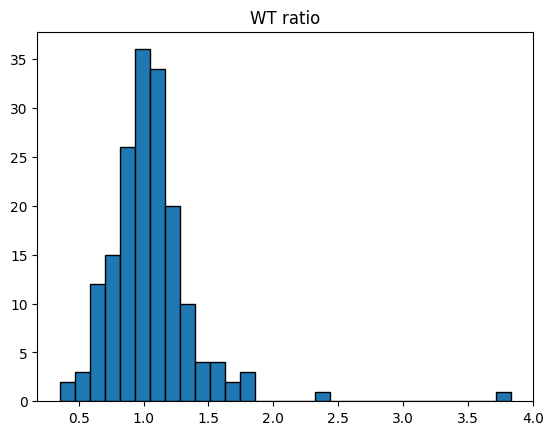

In [ ]:
plt.hist(wt_ratio_l, bins=30, edgecolor='black')
plt.title("WT ratio")
plt.show()

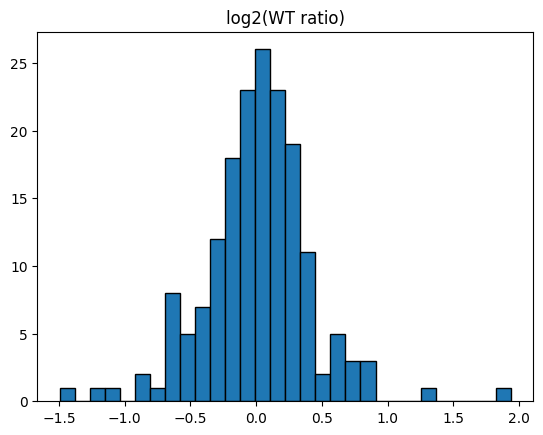

In [24]:
plt.hist(np.log2(wt_ratio_l), bins=30, edgecolor='black')
plt.title("log2(WT ratio)")
plt.show()

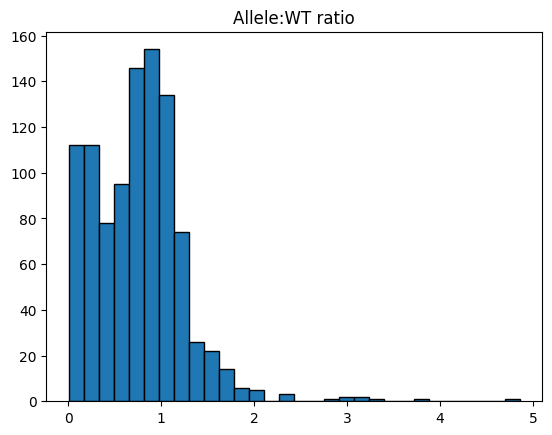

In [25]:
plt.hist(pDEST_DUAL_avg_allele_df['allele_wt_ratio'], bins=30, edgecolor='black')
plt.title("Allele:WT ratio")
plt.show()

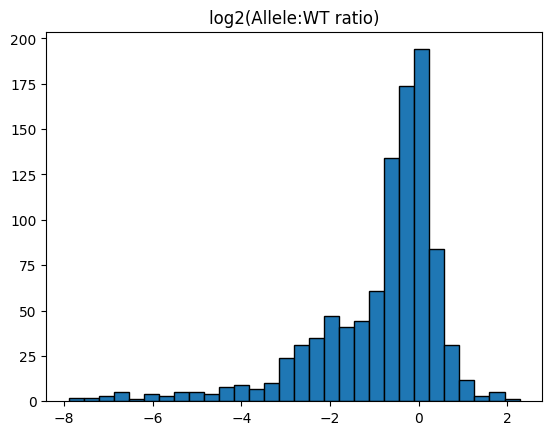

In [26]:
plt.hist(np.log2(pDEST_DUAL_avg_allele_df['allele_wt_ratio']), bins=30, edgecolor='black')
plt.title("log2(Allele:WT ratio)")
plt.show()

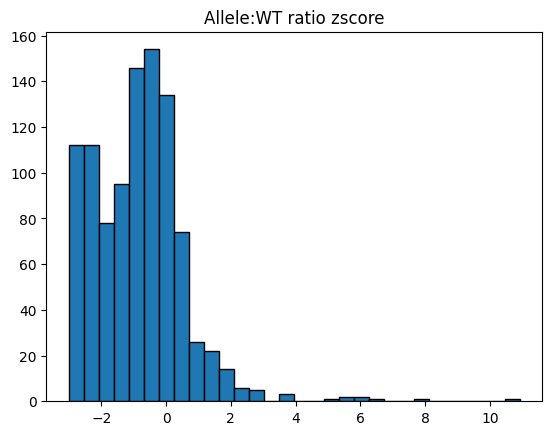

In [27]:
plt.hist(pDEST_DUAL_avg_allele_df['zscore'], bins=30, edgecolor='black')
plt.title("Allele:WT ratio zscore")
plt.show()

/Users/jewald/miniforge3/envs/dual-ipa/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


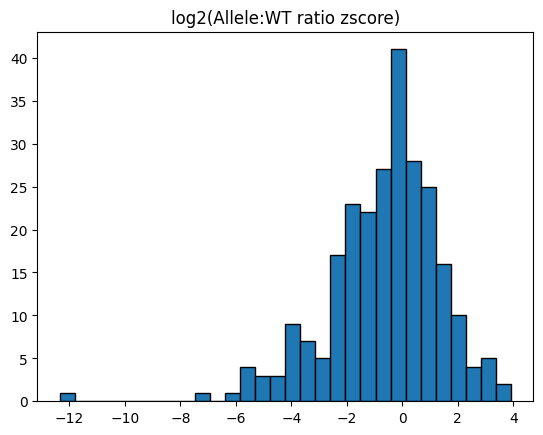

In [24]:
plt.hist(np.log2(pDEST_DUAL_avg_allele_df['zscore']), bins=30, edgecolor='black')
plt.title("log2(Allele:WT ratio zscore)")
plt.show()

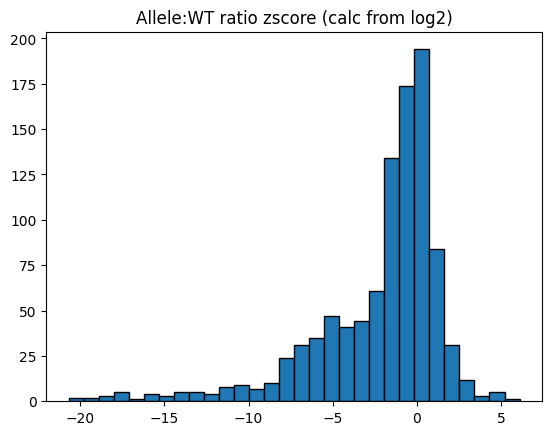

In [ ]:
plt.hist(pDEST_DUAL_avg_allele_df['zscore_log2'], bins=30, edgecolor='black')
plt.title("Allele:WT ratio zscore (calc from mean, log2)")
plt.show()

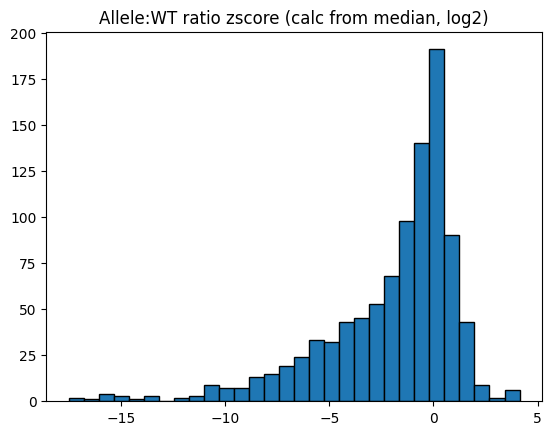

In [11]:
plt.hist(pDEST_DUAL_median_allele_df['zscore_log2'], bins=30, edgecolor='black')
plt.title("Allele:WT ratio zscore (calc from median, log2)")
plt.show()

In [13]:
pDEST_DUAL_median_allele_df.columns

Index(['symbol', 'node_type', 'nt_change', 'aa_change', 'pla', 'well',
       'coordinates', 'n_cells', 'orf_id', 'mut_id', 'valid_well',
       'median_gfp', 'median_mcherry', 'median_GFP_mCherry_ratio',
       'wt_GFP_mCherry_ratio_median', 'allele_wt_ratio_median',
       'zscore_median', 'zcat_median', 'zscore_log2'],
      dtype='object')

In [ ]:
import polars as pl
import matplotlib.pyplot as plt

dualipa = pl.DataFrame(pDEST_DUAL_avg_allele_df).with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("Variant")
).select(["Variant", "zscore_log2", "zscore", "mean_GFP"]).rename({
    "zscore_log2": "dualipa_zscore_log2",
    "zscore": "dualipa_zscore"
})

imaging = pl.read_csv("/Users/jewald/Desktop/mavedb_upload_sample_code/varchamp_data/inputs/2_abundance_changes.csv").select([
    "Variant", "U2OS_Z"
]).rename({
    "U2OS_Z": "imaging_zscore"
})

abun_df = dualipa.join(imaging, on="Variant").to_pandas()
print(abun_df.shape)


(426, 4)


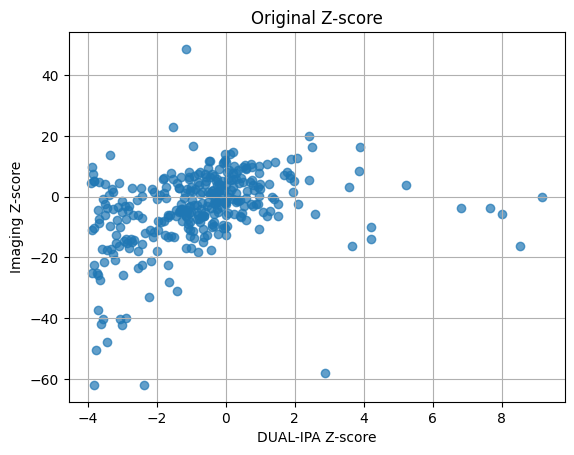

In [28]:
plt.scatter(abun_df['dualipa_zscore'], abun_df['imaging_zscore'], alpha=0.7)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score')
plt.title('Original Z-score')
plt.grid(True)
plt.show()

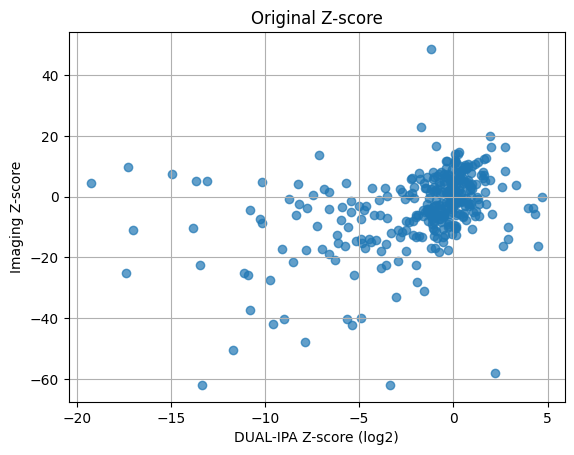

In [29]:
plt.scatter(abun_df['dualipa_zscore_log2'], abun_df['imaging_zscore'], alpha=0.7)
plt.ylabel('Imaging Z-score')
plt.xlabel('DUAL-IPA Z-score (log2)')
plt.title('Original Z-score')
plt.grid(True)
plt.show()